# Imcombine: uncertainties and flags

A deterministic check of the reduction contracts, without a statistical simulation or performance benchmark. Start with four-sample examples that can be checked by hand, then validate larger stacks with configurable image counts and sizes. Assertions stop the notebook when a contract fails.

We check mean, median, raw/normalized sums, rejection, missing errors, optional storage, chunking, and disk cache. Use the current Astropop checkout in the kernel environment.

In [1]:
%matplotlib inline
from contextlib import contextmanager
from pathlib import Path
from tempfile import TemporaryDirectory
import sys
import warnings

import numpy as np
import matplotlib.pyplot as plt
import astropop
from astropop.config import AstropopConfig as conf
from astropop.framedata import FrameData, PixelMaskFlags
from astropop.image.imcombine import imcombine

print("Python:", sys.version.split()[0])
print("Astropop:", astropop.__version__, Path(astropop.__file__).resolve())

@contextmanager
def storage_settings(disable_uncertainty=False, disable_flags=False):
    # Restore the kernel's previous settings even if an assertion fails.
    old = conf.FRAMEDATA_DISABLE_UNCERTAINTY, conf.FRAMEDATA_DISABLE_FLAGS
    conf.FRAMEDATA_DISABLE_UNCERTAINTY = disable_uncertainty
    conf.FRAMEDATA_DISABLE_FLAGS = disable_flags
    try:
        yield
    finally:
        conf.FRAMEDATA_DISABLE_UNCERTAINTY, conf.FRAMEDATA_DISABLE_FLAGS = old


Python: 3.14.8
Astropop: 0.9.5.dev103 /home/julio/Code/astropop/astropop/__init__.py


## A stack that can be checked by hand

Normal pixels contain `[10, 12, 14, 16]` ADU with standard deviations `[1, 2, 3, 4]` ADU. Special pixels exercise different exclusions:

- `(0, 0)`: a masked 100 ADU sample.
- `(0, 1)`: every input is masked.
- `(0, 2)`: one NaN sample.
- `(0, 3)`: all samples are 100 ADU, removed by minmax rejection.
- `(1, 1)`: one unmasked 100 ADU outlier.
- `(1, 2)`: a SATURATED flag without MASKED; it must still participate.

Imcombine uses MASKED to exclude samples. It does not copy all input status bits into the output; its output mask marks pixels with no accepted data (MASKED and UNSPECIFIED bits).

In [2]:
values = np.broadcast_to(np.array([10., 12., 14., 16.])[:, None, None], (4, 4, 4)).copy()
errors = np.broadcast_to(np.array([1., 2., 3., 4.])[:, None, None], values.shape).copy()
flags = np.zeros(values.shape, dtype=np.uint8)
values[3, 0, 0] = 100
flags[3, 0, 0] = PixelMaskFlags.MASKED.value
flags[:, 0, 1] = PixelMaskFlags.MASKED.value
values[1, 0, 2] = np.nan
values[:, 0, 3] = 100
values[3, 1, 1] = 100
flags[3, 1, 2] = PixelMaskFlags.SATURATED.value

# Each case gets new frames, created under the configuration being tested.
def make_frames(missing_error=False, dtype='float64'):
    return [FrameData(values[i].copy(), unit='adu', dtype=dtype,
                      uncertainty=None if missing_error and i == 0 else errors[i].copy(),
                      flags=flags[i].copy()) for i in range(len(values))]

for index in [(2, 2), (0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2)]:
    print(f"Pixel {index}: values={values[:, *index]}, flags={flags[:, *index]}")


Pixel (2, 2): values=[10. 12. 14. 16.], flags=[0 0 0 0]
Pixel (0, 0): values=[ 10.  12.  14. 100.], flags=[0 0 0 2]
Pixel (0, 1): values=[10. 12. 14. 16.], flags=[2 2 2 2]
Pixel (0, 2): values=[10. nan 14. 16.], flags=[0 0 0 0]
Pixel (0, 3): values=[100. 100. 100. 100.], flags=[0 0 0 0]
Pixel (1, 1): values=[ 10.  12.  14. 100.], flags=[0 0 0 0]
Pixel (1, 2): values=[10. 12. 14. 16.], flags=[ 0  0  0 16]


## An independent pixel-by-pixel reference

This deliberately simple reference does not call Astropop's reduction helpers. Mean and median errors use population scatter divided by `sqrt(n)`, rather than propagation of supplied errors. Sums propagate supplied errors in quadrature; if any input has no errors, they use scatter times `sqrt(n)` instead. Normalized sums multiply both data and errors by `total frames / accepted frames`.

For the ordinary pixel, mean and median are 13 ADU, with error `sqrt(5)/2` ADU. Raw sum is 52 ADU with error `sqrt(30)` ADU. The median error follows the existing implementation's estimator; this notebook does not claim it is the exact sampling error of a median.

In [3]:
def reference(method, filtering='none', normalize=False, missing_error=False,
              disable_flags=False):
    nominal = np.full(values.shape[1:], np.nan)
    uncertainty = np.full_like(nominal, np.nan)
    count = np.zeros(nominal.shape, dtype=int)
    for pixel in np.ndindex(nominal.shape):
        samples = values[:, *pixel]
        keep = ~np.isnan(samples)
        if not disable_flags:
            keep &= (flags[:, *pixel] & PixelMaskFlags.MASKED.value) == 0
        # A single sigma pass around the original valid samples, matching the
        # configured median/std strategy. These cases avoid boundary ambiguity.
        if filtering == 'sigma' and np.any(keep):
            accepted = samples[keep]
            keep &= np.abs(samples - np.median(accepted)) <= 2*np.std(accepted)
        if filtering == 'minmax':
            keep &= (samples >= 0) & (samples <= 30)
        accepted = samples[keep]
        n = count[pixel] = len(accepted)
        if n == 0:
            continue
        if method == 'sum':
            nominal[pixel] = np.sum(accepted)
            uncertainty[pixel] = (np.std(accepted)*np.sqrt(n) if missing_error
                                  else np.sqrt(np.sum(errors[:, *pixel][keep]**2)))
            if normalize:
                nominal[pixel] *= len(values)/n
                uncertainty[pixel] *= len(values)/n
        else:
            nominal[pixel] = np.mean(accepted) if method == 'mean' else np.median(accepted)
            uncertainty[pixel] = np.std(accepted)/np.sqrt(n)
    return nominal, uncertainty, count == 0

strategies = {
    'none': {},
    'minmax': {'minmax_clip': (0, 30)},
    'sigma': {'sigma_clip': 2, 'sigma_cen_func': 'median', 'sigma_dev_func': 'std'},
}
methods = [('mean', False), ('median', False), ('sum', False), ('sum', True)]


## Compare nominal values, uncertainties, and output masks

The compact table reports the largest absolute difference from the reference. All-NaN output pixels are checked too. Inputs must remain unchanged. The expected empty pixels may produce NumPy warnings about empty reductions; these warnings are captured locally and counted, not disabled globally.

In [4]:
results = {}
with storage_settings():
    with warnings.catch_warnings(record=True) as reduction_warnings:
        warnings.simplefilter('always')
        for filtering, options in strategies.items():
            for method, normalize in methods:
                for missing_error in (False, True):
                    frames = make_frames(missing_error)
                    snapshots = [(f.data.copy(), None if f.uncertainty is None else f.uncertainty.copy(),
                                  f.flags.copy()) for f in frames]
                    result = imcombine(frames, method=method, sum_normalize=normalize, **options)
                    expected = reference(method, filtering, normalize, missing_error)
                    np.testing.assert_allclose(result.data, expected[0], equal_nan=True)
                    np.testing.assert_allclose(result.uncertainty, expected[1], equal_nan=True)
                    np.testing.assert_array_equal(result.mask, expected[2])
                    expected_flags = expected[2].astype(np.uint8)*(PixelMaskFlags.MASKED | PixelMaskFlags.UNSPECIFIED).value
                    np.testing.assert_array_equal(result.flags, expected_flags)
                    assert str(result.unit) == 'adu'
                    for frame, (data, error, bits) in zip(frames, snapshots):
                        np.testing.assert_array_equal(frame.data, data)
                        np.testing.assert_array_equal(frame.flags, bits)
                        if error is None:
                            assert frame.uncertainty is None
                        else:
                            np.testing.assert_array_equal(frame.uncertainty, error)
                    key = (filtering, method, normalize, missing_error)
                    results[key] = result
                    data_delta = np.nanmax(np.abs(result.data - expected[0]))
                    error_delta = np.nanmax(np.abs(result.uncertainty - expected[1]))
                    print(f'{filtering:6s} {method:6s} normalized={normalize!s:5s} '
                          f'missing error={missing_error!s:5s} | '
                          f'data delta={data_delta:.2g}, error delta={error_delta:.2g}')
print(f'Passed {len(results)} comparisons; captured {len(reduction_warnings)} reduction warnings.')
print('Warning types:', sorted({type(w.message).__name__ for w in reduction_warnings}))


2026-10-19 15:42:48,796 astropop - INFO - Combining 4 images with mean method.  [imcombine]


2026-10-19 15:42:48,805 astropop - INFO - Combining 4 images with mean method.  [imcombine]


2026-10-19 15:42:48,816 astropop - INFO - Combining 4 images with median method.  [imcombine]


2026-10-19 15:42:48,831 astropop - INFO - Combining 4 images with median method.  [imcombine]


2026-10-19 15:42:48,843 astropop - INFO - Combining 4 images with sum method.  [imcombine]


...

2026-10-19 15:42:49,089 astropop - INFO - Combining 4 images with sum method.  [imcombine]


2026-10-19 15:42:49,093 astropop - INFO - Combination filters rejected 1 of 58 initially valid samples (1.72%).  [imcombine]


2026-10-19 15:42:49,101 astropop - INFO - Combining 4 images with sum method.  [imcombine]


2026-10-19 15:42:49,105 astropop - INFO - Combination filters rejected 1 of 58 initially valid samples (1.72%).  [imcombine]


sigma  mean   normalized=False missing error=True  | data delta=0, error delta=0
sigma  median normalized=False missing error=False | data delta=0, error delta=0
sigma  median normalized=False missing error=True  | data delta=0, error delta=0
sigma  sum    normalized=False missing error=False | data delta=0, error delta=0
sigma  sum    normalized=False missing error=True  | data delta=0, error delta=0
sigma  sum    normalized=True  missing error=False | data delta=0, error delta=0
sigma  sum    normalized=True  missing error=True  | data delta=0, error delta=0
Passed 24 comparisons; captured 12 reduction warnings.
Warning types: ['RuntimeWarning']


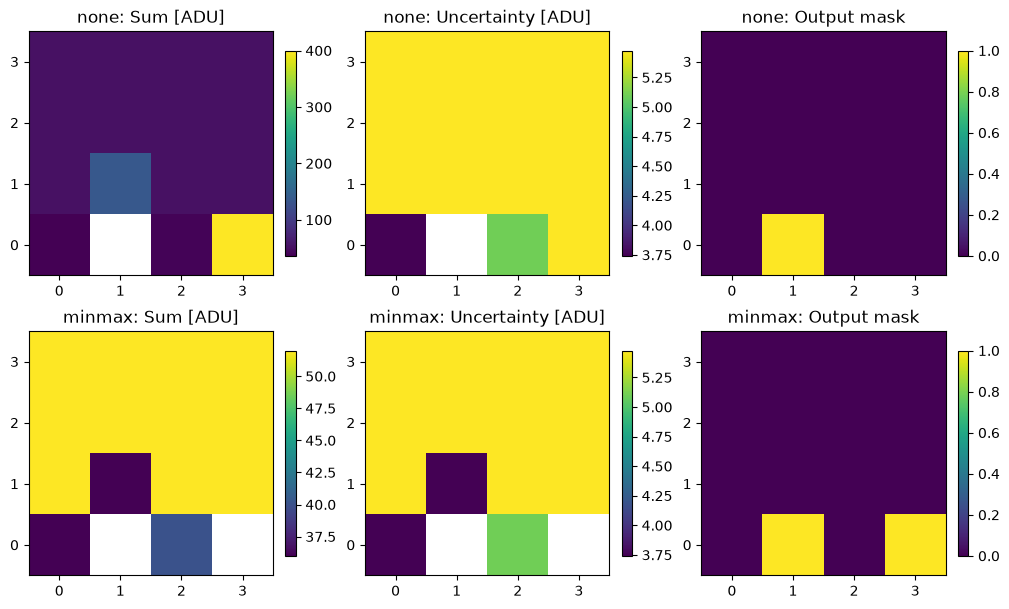

In [5]:
# One visual comparison: raw sum, with all input uncertainties present.
fig, axes = plt.subplots(2, 3, figsize=(10, 6), constrained_layout=True)
for row, filtering in enumerate(('none', 'minmax')):
    result = results[(filtering, 'sum', False, False)]
    for col, (array, label) in enumerate(((result.data, 'Sum [ADU]'),
                                         (result.uncertainty, 'Uncertainty [ADU]'),
                                         (result.mask, 'Output mask'))):
        image = axes[row, col].imshow(array, origin='lower', interpolation='nearest')
        axes[row, col].set_title(f'{filtering}: {label}')
        axes[row, col].set_xticks(range(4))
        axes[row, col].set_yticks(range(4))
        fig.colorbar(image, ax=axes[row, col], shrink=0.8)
plt.show()


## Optional uncertainty and flag storage

Test all four configurations, creating the frames inside each configuration. Disabled uncertainties must return `None`; nominal values and masks must still agree. Disabled flags must return `None` for both flags and mask, and input MASKED samples then participate. Algorithmic rejection continues to work independently of flag storage.

In [6]:
with warnings.catch_warnings(record=True):
    warnings.simplefilter('always')
    for disable_uncertainty in (False, True):
        for disable_flags in (False, True):
            with storage_settings(disable_uncertainty, disable_flags):
                frames = make_frames()
                if disable_uncertainty:
                    assert all(f.uncertainty is None for f in frames)
                if disable_flags:
                    assert all(f.flags is None and f.mask is None for f in frames)
                for method, normalize in methods:
                    result = imcombine(frames, method=method, sum_normalize=normalize,
                                       **strategies['minmax'])
                    expected = reference(method, 'minmax', normalize, disable_flags=disable_flags)
                    np.testing.assert_allclose(result.data, expected[0], equal_nan=True)
                    if disable_uncertainty:
                        assert result.uncertainty is None
                    else:
                        np.testing.assert_allclose(result.uncertainty, expected[1], equal_nan=True)
                    if disable_flags:
                        assert result.flags is None and result.mask is None
                    else:
                        np.testing.assert_array_equal(result.mask, expected[2])
            print(f'PASS: disable_uncertainty={disable_uncertainty}, disable_flags={disable_flags}')


2026-10-19 15:42:50,163 astropop - INFO - Combining 4 images with mean method.  [imcombine]


2026-10-19 15:42:50,165 astropop - INFO - Combination filters rejected 5 of 58 initially valid samples (8.62%).  [imcombine]


2026-10-19 15:42:50,168 astropop - INFO - Combining 4 images with median method.  [imcombine]


2026-10-19 15:42:50,170 astropop - INFO - Combination filters rejected 5 of 58 initially valid samples (8.62%).  [imcombine]


2026-10-19 15:42:50,174 astropop - INFO - Combining 4 images with sum method.  [imcombine]


...

2026-10-19 15:42:50,243 astropop - INFO - Combining 4 images with sum method.  [imcombine]


2026-10-19 15:42:50,244 astropop - INFO - Combination filters rejected 6 of 63 initially valid samples (9.52%).  [imcombine]


2026-10-19 15:42:50,247 astropop - INFO - Combining 4 images with sum method.  [imcombine]


2026-10-19 15:42:50,249 astropop - INFO - Combination filters rejected 6 of 63 initially valid samples (9.52%).  [imcombine]


PASS: disable_uncertainty=False, disable_flags=False
PASS: disable_uncertainty=False, disable_flags=True
PASS: disable_uncertainty=True, disable_flags=False
PASS: disable_uncertainty=True, disable_flags=True


## Chunking and disk cache must preserve the result

Repeat the filtered calculations with small and large memory budgets, RAM and disk cache, and float32/float64 storage. The budgets are small because the entire fixture is tiny; these are correctness checks, not memory benchmarks. Temporary disk files are confined to a disposable directory.

In [7]:
checks = 0
with storage_settings(), TemporaryDirectory(prefix='imcombine-check-') as temporary:
    with warnings.catch_warnings(record=True):
        warnings.simplefilter('always')
        for dtype in ('float32', 'float64'):
            for disk_cache in (False, True):
                for budget in (128, 10**9):
                    for method, normalize in methods:
                        cache = Path(temporary)/f'case_{checks}'
                        result = imcombine(make_frames(dtype=dtype), method=method,
                                           sum_normalize=normalize, dtype=dtype,
                                           memory_limit=budget, use_disk_cache=disk_cache,
                                           tmp_dir=str(cache), **strategies['minmax'])
                        expected = reference(method, 'minmax', normalize)
                        np.testing.assert_allclose(result.data, expected[0], rtol=1e-6, equal_nan=True)
                        np.testing.assert_allclose(result.uncertainty, expected[1], rtol=1e-6, equal_nan=True)
                        np.testing.assert_array_equal(result.mask, expected[2])
                        assert result.data.dtype == np.dtype(dtype)
                        assert result.uncertainty.dtype == np.dtype(dtype)
                        assert not cache.exists() or not list(cache.iterdir())
                        checks += 1
print(f'Passed {checks} storage/chunking comparisons.')


2026-10-19 15:42:50,264 astropop - INFO - Combining 4 images with mean method.  [imcombine]


2026-10-19 15:42:50,272 astropop - INFO - Combination filters rejected 5 of 58 initially valid samples (8.62%).  [imcombine]


2026-10-19 15:42:50,278 astropop - INFO - Combining 4 images with median method.  [imcombine]


2026-10-19 15:42:50,288 astropop - INFO - Combination filters rejected 5 of 58 initially valid samples (8.62%).  [imcombine]


2026-10-19 15:42:50,298 astropop - INFO - Combining 4 images with sum method.  [imcombine]


...

2026-10-19 15:42:50,767 astropop - INFO - Combining 4 images with sum method.  [imcombine]


2026-10-19 15:42:50,768 astropop - INFO - Combination filters rejected 5 of 58 initially valid samples (8.62%).  [imcombine]


2026-10-19 15:42:50,775 astropop - INFO - Combining 4 images with sum method.  [imcombine]


2026-10-19 15:42:50,777 astropop - INFO - Combination filters rejected 5 of 58 initially valid samples (8.62%).  [imcombine]


Passed 32 storage/chunking comparisons.


## Larger images and image counts

Keep the tiny examples above as a readable reference, then exercise the same rules on **100 images of 512 × 512 pixels**. Change the parameters below for camera-sized images, for example `large_shape = (1024, 1024)`.

The stack has a fixed bias level, seeded read noise, per-frame uncertainties, masked samples, a completely masked patch, NaNs, and cosmic-ray-like outliers. A SATURATED bit alone is also present. An independent NumPy reference checks every output pixel. These are correctness comparisons, not performance benchmarks; the reference itself allocates a floating stack and is not memory bounded.

In [8]:
# Configurable larger-stack validation.
n_images = 100
large_shape = (512, 512)
large_dtype = 'float32'
large_memory_limit = 32 * 1024**2
seed = 42
bias_level = 1000.0
read_noise = 5.0
cosmic_amplitude = 500.0
cosmics_per_image = 20

assert n_images >= 4 and min(large_shape) >= 8
rng = np.random.default_rng(seed)
large_values = rng.normal(bias_level, read_noise, (n_images, *large_shape)).astype(large_dtype)
large_errors = np.linspace(4, 6, n_images, dtype=large_dtype)
large_flags = np.zeros(large_values.shape, dtype=np.uint8)
large_flags[:, :4, :4] = PixelMaskFlags.MASKED.value
large_flags[::2, 8:16, 8:16] = PixelMaskFlags.MASKED.value
large_flags[-1, 16:24, 16:24] = PixelMaskFlags.SATURATED.value
large_values[0, -1, -1] = np.nan
for index in range(n_images):
    y = rng.integers(4, large_shape[0], cosmics_per_image)
    x = rng.integers(4, large_shape[1], cosmics_per_image)
    large_values[index, y, x] += cosmic_amplitude
print(f'{n_images} images, {large_shape[0]} × {large_shape[1]} pixels, {large_dtype}')
print(f'Input data + flags: {(large_values.nbytes + large_flags.nbytes)/1024**2:.1f} MiB '
      '(excludes frames, reference, and combination workspaces).')

large_strategies = {
    'none': {},
    'minmax': {'minmax_clip': (bias_level - 50, bias_level + 50)},
    'sigma': {'sigma_clip': 3, 'sigma_cen_func': 'median', 'sigma_dev_func': 'std'},
}

def large_frames():
    return [FrameData(large_values[i].copy(), dtype=large_dtype, unit='adu',
                      uncertainty=float(large_errors[i]), flags=large_flags[i].copy())
            for i in range(n_images)]


def large_reference(filtering, disable_flags=False):
    # Use straightforward NaN reductions, independent of the
    # combiner's chunked Boolean-mask implementation. Error estimates and
    # final reference reductions use float64; clipping centers preserve
    # the stored-data median rounding.
    work = large_values.astype('float64')
    if not disable_flags:
        work[(large_flags & PixelMaskFlags.MASKED.value) != 0] = np.nan
    if filtering == 'minmax':
        low, high = large_strategies[filtering]['minmax_clip']
        work[(work < low) | (work > high)] = np.nan
    elif filtering == 'sigma':
        # The selected middle pair is averaged in the storage dtype. Match
        # that rounding before testing a potentially borderline sample.
        center = np.nanmedian(work.astype(large_dtype), axis=0).astype('float64')
        deviation = np.nanstd(work, axis=0)
        work[(work < center - 3*deviation) | (work > center + 3*deviation)] = np.nan
    valid = ~np.isnan(work)
    count = valid.sum(axis=0)
    empty = count == 0
    scatter = np.nanstd(work, axis=0)
    error_mean = scatter/np.sqrt(np.maximum(count, 1))
    variance = np.broadcast_to(large_errors.astype('float64')[:, None, None]**2, valid.shape)
    error_sum = np.sqrt(np.sum(variance, axis=0, where=valid))
    error_sum[empty] = np.nan
    total = np.nansum(work, axis=0)
    total[empty] = np.nan
    return {'mean': (np.nanmean(work, axis=0), error_mean),
            'median': (np.nanmedian(work, axis=0), error_mean),
            'sum': (total, error_sum)}, empty


100 images, 512 × 512 pixels, float32
Input data + flags: 125.0 MiB (excludes frames, reference, and combination workspaces).


In [9]:
large_results = {}
with storage_settings(), warnings.catch_warnings(record=True) as large_warnings:
    warnings.simplefilter('always')
    for filtering, options in large_strategies.items():
        expected, empty = large_reference(filtering)
        frames = large_frames()
        for method in ('mean', 'median', 'sum'):
            result = imcombine(frames, method=method, sum_normalize=False,
                               dtype=large_dtype, memory_limit=large_memory_limit, **options)
            # Permit float32 storage/reduction rounding, relative to the
            # independent float64 reference. This is not a sampling tolerance.
            np.testing.assert_allclose(result.data, expected[method][0], rtol=2e-6, equal_nan=True)
            np.testing.assert_allclose(result.uncertainty, expected[method][1], rtol=2e-6, equal_nan=True)
            np.testing.assert_array_equal(result.mask, empty)
            bits = empty.astype(np.uint8)*(PixelMaskFlags.MASKED | PixelMaskFlags.UNSPECIFIED).value
            np.testing.assert_array_equal(result.flags, bits)
            large_results[filtering, method] = result
            print(f'PASS: {filtering:6s} {method:6s} — all {result.data.size:,} pixels')
        del frames
print(f'Captured {len(large_warnings)} warnings, including deliberately empty reference pixels.')


2026-10-19 15:42:55,302 astropop - INFO - Combining 100 images with mean method.  [imcombine]


2026-10-19 15:42:55,870 astropop - INFO - Combining 100 images with median method.  [imcombine]


PASS: none   mean   — all 262,144 pixels


2026-10-19 15:42:56,588 astropop - INFO - Combining 100 images with sum method.  [imcombine]


PASS: none   median — all 262,144 pixels


...

2026-10-19 15:43:12,093 astropop - INFO - Combination filters rejected 67844 of 26209599 initially valid samples (0.26%).  [imcombine]


2026-10-19 15:43:12,179 astropop - INFO - Combining 100 images with sum method.  [imcombine]


PASS: sigma  median — all 262,144 pixels


2026-10-19 15:43:12,900 astropop - INFO - Combination filters rejected 67844 of 26209599 initially valid samples (0.26%).  [imcombine]


PASS: sigma  sum    — all 262,144 pixels
Captured 77 warnings, including deliberately empty reference pixels.


### Optional storage on the larger stack

Run the filtered sum in all four configurations. The independent reference changes its input validity when flags are disabled. Uncertainty storage can be disabled independently, without changing nominal values. The small checks above also cover missing errors and normalized sums.

In [10]:
with warnings.catch_warnings(record=True):
    warnings.simplefilter('always')
    for disable_flags in (False, True):
        expected, empty = large_reference('minmax', disable_flags)
        for disable_uncertainty in (False, True):
            with storage_settings(disable_uncertainty, disable_flags):
                frames = large_frames()
                result = imcombine(frames, method='sum', sum_normalize=False,
                                   dtype=large_dtype, memory_limit=large_memory_limit,
                                   **large_strategies['minmax'])
                np.testing.assert_allclose(result.data, expected['sum'][0], rtol=2e-6, equal_nan=True)
                if disable_uncertainty:
                    assert result.uncertainty is None
                else:
                    np.testing.assert_allclose(result.uncertainty, expected['sum'][1], rtol=2e-6, equal_nan=True)
                if disable_flags:
                    assert result.flags is None and result.mask is None
                else:
                    np.testing.assert_array_equal(result.mask, empty)
                del frames
            print(f'PASS: larger stack, disable_flags={disable_flags}, '
                  f'disable_uncertainty={disable_uncertainty}')


2026-10-19 15:43:16,307 astropop - INFO - Combining 100 images with sum method.  [imcombine]


2026-10-19 15:43:16,564 astropop - INFO - Combination filters rejected 2000 of 26209599 initially valid samples (0.01%).  [imcombine]


2026-10-19 15:43:16,675 astropop - INFO - Combining 100 images with sum method.  [imcombine]


PASS: larger stack, disable_flags=False, disable_uncertainty=False


2026-10-19 15:43:16,799 astropop - INFO - Combination filters rejected 2000 of 26209599 initially valid samples (0.01%).  [imcombine]


...

2026-10-19 15:43:20,486 astropop - INFO - Combination filters rejected 2000 of 26214399 initially valid samples (0.01%).  [imcombine]


2026-10-19 15:43:20,586 astropop - INFO - Combining 100 images with sum method.  [imcombine]


PASS: larger stack, disable_flags=True, disable_uncertainty=False


2026-10-19 15:43:20,706 astropop - INFO - Combination filters rejected 2000 of 26214399 initially valid samples (0.01%).  [imcombine]


PASS: larger stack, disable_flags=True, disable_uncertainty=True


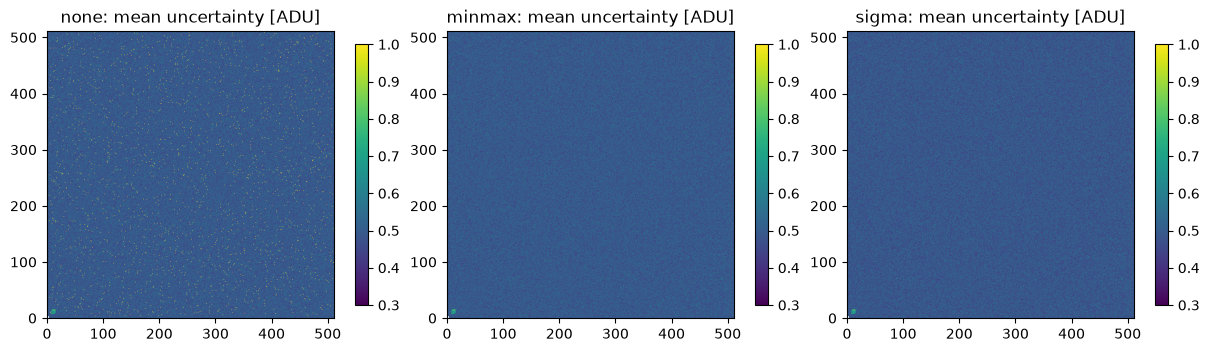

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for axis, filtering in zip(axes, large_strategies):
    uncertainty = large_results[filtering, 'mean'].uncertainty
    image = axis.imshow(uncertainty, origin='lower', vmin=0.3, vmax=1.0)
    axis.set_title(f'{filtering}: mean uncertainty [ADU]')
    fig.colorbar(image, ax=axis, shrink=0.8)
plt.show()
# Without clipping, cosmic rays increase the scatter-based uncertainty.
# Compare at the same color scale; assertions above check the full arrays.


## Reading the result

If every assertion passes:

- Mean and median errors follow the scatter estimator; supplied per-image errors drive sums only when all inputs provide them.
- Masks, NaNs, and rejection remove the same samples from nominal and uncertainty calculations. Normalization scales both consistently.
- Only MASKED excludes an input sample. A SATURATED bit alone does not exclude it, and input status bits are not propagated to the combined image.
- Pixels with no accepted samples are NaN and masked with floating output storage. Disabling flags removes the mask storage, while rejection still works.
- Disabling uncertainties removes their storage without changing nominal values. Configuration is restored after each check.
- Results agree across the tested chunks, cache backends, and floating dtypes, without modifying source arrays.

These are deterministic behavioral checks, not a proof of calibration accuracy or of the statistical quality of a particular uncertainty estimator. Integer quantization and large-camera performance belong in the separate combination study.